In [33]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

## Tấn Hiệp – Demo 5: Xoay ảnh (warping ngược, nội suy)



In [34]:
def tao_ban_co(kich_thuoc=200, o=25, sang=220, toi=60):
    ban_co = np.zeros((kich_thuoc, kich_thuoc), dtype=np.uint8)
    for y in range(kich_thuoc):
        for x in range(kich_thuoc):
            if (x // o + y // o) % 2 == 0:
                ban_co[y, x] = sang
            else:
                ban_co[y, x] = toi
    return ban_co


def ma_tran_xoay(goc_do, cx, cy):
    t = np.deg2rad(goc_do)
    c, s = np.cos(t), np.sin(t)

    T_ve_goc = np.array([[1, 0, -cx],
                         [0, 1, -cy],
                         [0, 0, 1]])
    R = np.array([[c, s, 0],
                  [-s, c, 0],
                  [0, 0, 1]])
    T_ve_tam = np.array([[1, 0, cx],
                         [0, 1, cy],
                         [0, 0, 1]])

    return T_ve_tam @ R @ T_ve_goc


ban_co = tao_ban_co()
h, w = ban_co.shape
cx, cy = (w - 1) / 2, (h - 1) / 2

M = ma_tran_xoay(30, cx, cy)
tam_sau_xoay = M @ np.array([cx, cy, 1])
print("Ma trận xoay 30 độ:\n", np.round(M, 3))
print(f"Tâm trước khi xoay: ({cx:.2f}, {cy:.2f})")
print(f"Tâm sau khi xoay:  ({tam_sau_xoay[0]:.2f}, {tam_sau_xoay[1]:.2f})")
print("Tâm không đổi:", "Có" if np.allclose(tam_sau_xoay[:2], [cx, cy]) else "Không")

Ma trận xoay 30 độ:
 [[  0.866   0.5   -36.42 ]
 [ -0.5     0.866  63.08 ]
 [  0.      0.      1.   ]]
Tâm trước khi xoay: (99.50, 99.50)
Tâm sau khi xoay:  (99.50, 99.50)
Tâm không đổi: Có


In [35]:
def lay_gan_nhat(anh, x, y):
    h, w = anh.shape
    xi = int(np.round(x))
    yi = int(np.round(y))
    if xi < 0 or xi >= w or yi < 0 or yi >= h:
        return 0.0
    return float(anh[yi, xi])


def lay_song_tuyen(anh, x, y):
    h, w = anh.shape
    eps = 1e-6
    if x < -eps or x > w - 1 + eps or y < -eps or y > h - 1 + eps:
        return 0.0

    x = min(max(x, 0.0), w - 1)
    y = min(max(y, 0.0), h - 1)

    x0 = int(np.floor(x))
    y0 = int(np.floor(y))
    x1 = min(x0 + 1, w - 1)
    y1 = min(y0 + 1, h - 1)

    dx = x - x0
    dy = y - y0

    Q11 = float(anh[y0, x0])
    Q21 = float(anh[y0, x1])
    Q12 = float(anh[y1, x0])
    Q22 = float(anh[y1, x1])

    R1 = (1 - dx) * Q11 + dx * Q21
    R2 = (1 - dx) * Q12 + dx * Q22
    P = (1 - dy) * R1 + dy * R2
    return P


def xoay_anh(anh, goc_do, kieu="song_tuyen"):
    if kieu == "gan_nhat":
        lay_mau = lay_gan_nhat
    elif kieu == "song_tuyen":
        lay_mau = lay_song_tuyen
    else:
        raise ValueError("kieu phải là 'gan_nhat' hoặc 'song_tuyen'")

    h, w = anh.shape
    M = ma_tran_xoay(goc_do, (w - 1) / 2, (h - 1) / 2)
    M_nguoc = np.linalg.inv(M)

    ket_qua = np.zeros((h, w), dtype=np.float64)
    for y_dich in range(h):
        for x_dich in range(w):
            x_nguon, y_nguon, _ = M_nguoc @ np.array([x_dich, y_dich, 1.0])
            ket_qua[y_dich, x_dich] = lay_mau(anh, x_nguon, y_nguon)

    return np.clip(np.round(ket_qua), 0, 255).astype(np.uint8)

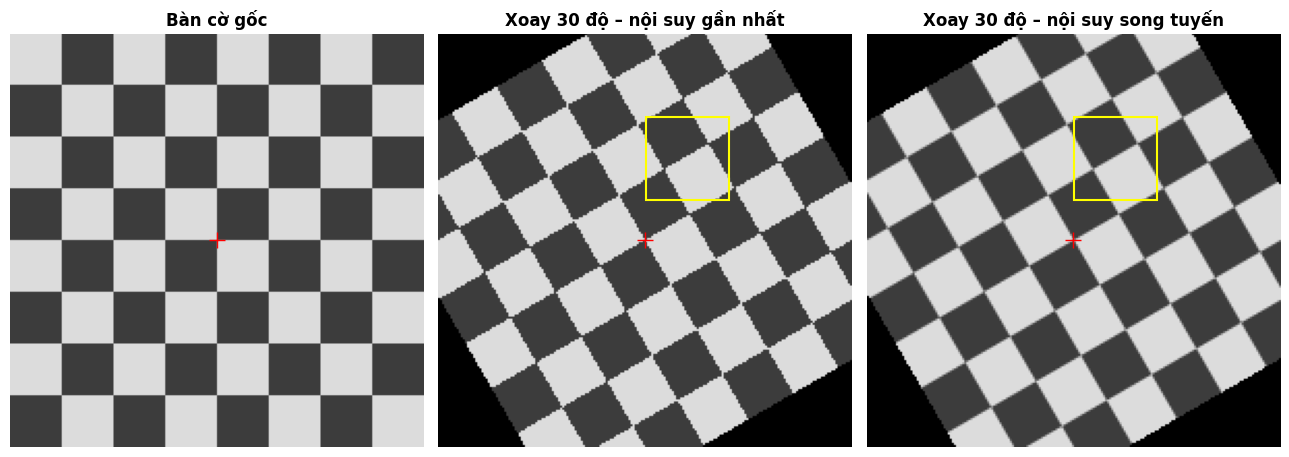

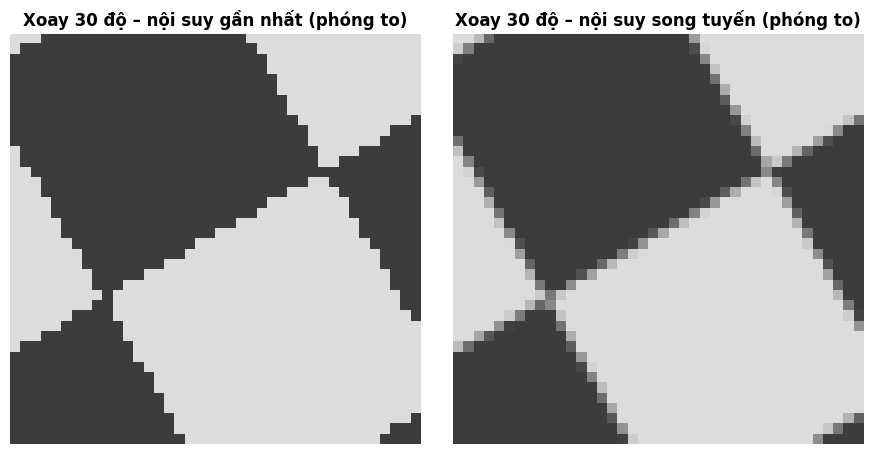

In [36]:
goc = 30
anh_gan_nhat = xoay_anh(ban_co, goc, "gan_nhat")
anh_song_tuyen = xoay_anh(ban_co, goc, "song_tuyen")

anh_list = [ban_co, anh_gan_nhat, anh_song_tuyen]
ten_list = ["Bàn cờ gốc", f"Xoay {goc} độ – nội suy gần nhất", f"Xoay {goc} độ – nội suy song tuyến"]

y1, y2, x1, x2 = 40, 80, 100, 140

plt.figure(figsize=(13, 4.5))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(anh_list[i], cmap="gray", vmin=0, vmax=255)
    plt.plot(cx, cy, "r+", markersize=12)
    if i > 0:
        plt.gca().add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                          fill=False, edgecolor="yellow", linewidth=1.5))
    plt.title(ten_list[i], fontsize=12, fontweight="bold")
    plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4.5))
for i in range(1, 3):
    plt.subplot(1, 2, i)
    plt.imshow(anh_list[i][y1:y2, x1:x2], cmap="gray", vmin=0, vmax=255,
               interpolation="nearest")
    plt.title(ten_list[i] + " (phóng to)", fontsize=12, fontweight="bold")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [37]:
M_cv = cv2.getRotationMatrix2D((cx, cy), goc, 1.0)
cv_gan_nhat = cv2.warpAffine(ban_co, M_cv, (w, h), flags=cv2.INTER_NEAREST)
cv_song_tuyen = cv2.warpAffine(ban_co, M_cv, (w, h), flags=cv2.INTER_LINEAR)

print("Ma trận tự xây trùng với OpenCV:", "Có" if np.allclose(ma_tran_xoay(goc, cx, cy)[:2], M_cv) else "Không")
print("Gần nhất   - sai lệch trung bình so với OpenCV:",
      round(np.mean(np.abs(anh_gan_nhat.astype(int) - cv_gan_nhat)), 4))
print("Song tuyến - sai lệch trung bình so với OpenCV:",
      round(np.mean(np.abs(anh_song_tuyen.astype(int) - cv_song_tuyen)), 4))

Ma trận tự xây trùng với OpenCV: Có
Gần nhất   - sai lệch trung bình so với OpenCV: 0.0
Song tuyến - sai lệch trung bình so với OpenCV: 0.6021


In [38]:
anh_sang = np.full((200, 200), 200, dtype=np.uint8)

ten_kieu = {"gan_nhat": "gần nhất", "song_tuyen": "song tuyến"}

for goc_thu, k in [(0, 0), (90, 1), (180, 2), (270, 3), (360, 0)]:
    for kieu in ["gan_nhat", "song_tuyen"]:
        kq_sang = xoay_anh(anh_sang, goc_thu, kieu)
        kq_ban_co = xoay_anh(ban_co, goc_thu, kieu)
        so_den = int(np.sum(kq_sang == 0))
        dung_rot90 = np.array_equal(kq_ban_co, np.rot90(ban_co, k))
        ket_luan = "Có" if dung_rot90 else "Không"
        print(f"{goc_thu:3d} độ {ten_kieu[kieu]:10s}: {so_den} pixel đen, "
              f"trùng với np.rot90 (k={k}): {ket_luan}")

  0 độ gần nhất  : 0 pixel đen, trùng với np.rot90 (k=0): Có
  0 độ song tuyến: 0 pixel đen, trùng với np.rot90 (k=0): Có
 90 độ gần nhất  : 0 pixel đen, trùng với np.rot90 (k=1): Có
 90 độ song tuyến: 0 pixel đen, trùng với np.rot90 (k=1): Có
180 độ gần nhất  : 0 pixel đen, trùng với np.rot90 (k=2): Có
180 độ song tuyến: 0 pixel đen, trùng với np.rot90 (k=2): Có
270 độ gần nhất  : 0 pixel đen, trùng với np.rot90 (k=3): Có
270 độ song tuyến: 0 pixel đen, trùng với np.rot90 (k=3): Có
360 độ gần nhất  : 0 pixel đen, trùng với np.rot90 (k=0): Có
360 độ song tuyến: 0 pixel đen, trùng với np.rot90 (k=0): Có


In [39]:
cv2.imwrite("../images/xoay_gan_nhat.png", anh_gan_nhat)
cv2.imwrite("../images/xoay_song_tuyen.png", anh_song_tuyen)
print("Đã lưu: ../images/xoay_gan_nhat.png, ../images/xoay_song_tuyen.png")

Đã lưu: ../images/xoay_gan_nhat.png, ../images/xoay_song_tuyen.png


## KT3 – Hough đa tỉ lệ


Nạp các hàm dùng chung từ notebook của Lên và Gấm. Chỉ lấy định nghĩa hàm, không chạy các ô demo hay ghi ảnh của hai notebook.

In [40]:
import ast
import json
from pathlib import Path

thu_muc = Path.cwd()
if not (thu_muc / "len.ipynb").is_file():
    thu_muc = thu_muc / "lam_viec"

ham_dung_chung = {
    "len.ipynb": {"convolve2d", "smooth_accumulator", "hough_accumulate", "find_peaks"},
    "gam.ipynb": {"angle_error", "rho_error"}
}

for ten_file, cac_ten_ham in ham_dung_chung.items():
    with open(thu_muc / ten_file, encoding="utf-8") as file:
        noi_dung = json.load(file)
    da_nap = set()
    for o in noi_dung["cells"]:
        if o["cell_type"] != "code":
            continue
        cay = ast.parse("".join(o["source"]))
        for ham in cay.body:
            if isinstance(ham, ast.FunctionDef) and ham.name in cac_ten_ham:
                ma = ast.Module(body=[ham], type_ignores=[])
                exec(compile(ma, str(thu_muc / ten_file), "exec"), globals())
                da_nap.add(ham.name)
    if da_nap != cac_ten_ham:
        raise NameError(f"Thiếu hàm trong {ten_file}: {cac_ten_ham - da_nap}")


In [41]:
def hough_multiscale(edges, grad_dir, n_levels=2, refine_factor=8,
                     n_peaks=10, rho_step=2.0, theta_step_deg=1.0,
                     delta_deg=10.0):


    edges = np.asarray(edges)
    if edges.ndim != 2:
        raise ValueError("edges phải là ảnh hai chiều")
    if int(n_levels) != n_levels or n_levels < 0:
        raise ValueError("n_levels phải là số nguyên không âm")
    if int(refine_factor) != refine_factor or refine_factor <= 1:
        raise ValueError("refine_factor phải là số nguyên lớn hơn 1")
    if rho_step <= 0 or not 0 < theta_step_deg < 180:
        raise ValueError("Bước rho và theta không hợp lệ")
    n_levels = int(n_levels)
    refine_factor = int(refine_factor)
    if grad_dir is not None:
        grad_dir = np.asarray(grad_dir)

    h, w = edges.shape
    ys, xs = np.nonzero(edges)
    if len(xs) == 0:
        return []

    D = np.ceil(np.sqrt(h*h + w*w) / rho_step) * rho_step
    n_rho = int(round(2 * D / rho_step)) + 1
    n_theta = int(np.ceil(180 / theta_step_deg))
    A, thetas, rhos = hough_accumulate(
        edges, (0, np.pi), (-D, D), n_theta, n_rho,
        grad_dir=grad_dir, delta_deg=delta_deg)
    peaks = find_peaks(A, n_peaks, thetas=thetas, rhos=rhos)
    ket_qua = []

    for rho, theta, _ in peaks:
        rho_diem = xs * np.cos(theta) + ys * np.sin(theta)
        chi_so = np.rint((rho_diem + D) / rho_step).astype(int)
        o_rho = int(round((rho + D) / rho_step))
        chon = chi_so == o_rho
        if grad_dir is not None:
            g = np.asarray(grad_dir)[ys, xs]
            lech = np.abs((g - theta + np.pi / 2) % np.pi - np.pi / 2)
            chon &= lech <= np.deg2rad(delta_deg)
        if not np.any(chon):
            continue

        canh_chon = np.zeros_like(edges, dtype=bool)
        canh_chon[ys[chon], xs[chon]] = True
        dr, dt = rho_step, np.pi / n_theta

        for _ in range(n_levels):
            rho_range = (rho - dr, rho + dr)
            theta_range = (theta - dt, theta + dt + dt / refine_factor)
            A_moi, t_moi, r_moi = hough_accumulate(
                canh_chon, theta_range, rho_range,
                2 * refine_factor + 1, 2 * refine_factor + 1,
                grad_dir=grad_dir, delta_deg=delta_deg)
            dinh_moi = find_peaks(A_moi, 1, thetas=t_moi, rhos=r_moi)
            if not dinh_moi:
                break
            rho, theta, _ = dinh_moi[0]
            dr /= refine_factor
            dt /= refine_factor


        while theta < 0:
            theta += np.pi
            rho = -rho
        while theta >= np.pi:
            theta -= np.pi
            rho = -rho

        ket_qua.append((float(rho), float(theta)))

    return ket_qua


## Kiểm thử hai góc 0.5 độ và 179.5 độ

Dùng ảnh và hàm đo sai số của Gấm. Ô kiểm thử chỉ chạy các hàm của nhóm: Hough đa tỉ lệ và Hough thô bước 1 độ (`n_levels=0`). Kiểm tra khoảng góc, dấu rho và sai số góc; báo cả trường hợp chưa đạt. Ô đối chiếu thư viện riêng bên dưới gọi OpenCV, lập bảng so sánh và vẽ kết quả.


### Có dùng AI hỗ trợ
Công cụ: Codex

Mục đích: Dựng thí nghiệm kiểm thử hai góc 0.5 độ và 179.5 độ; so sánh với Hough thô bước 1 độ, lập bảng sai số góc và rho, vẽ ảnh cùng đường chuẩn và đường phát hiện.

Prompt:
> sử dụng các hàm có sẵn để kiểm thử ảnh chứa đường ở góc 0.5 và 179.5, đối chiếu với Hough thô bước 1, lập bảng sai số góc và rho, vẽ ảnh cùng đường chuẩn và kết quả phát hiện, không thay đổi các hàm cài đặt, nêu rõ dữ liệu và tham số thí nghiệm đã dùng, báo cả trường hợp không đạt và chỉ sử dụng thư viện được đề cho phép.



In [42]:
thu_muc_anh = thu_muc.parent / "images"
cac_ca = [("hough_angle_0_5.png", 200.0, 0.5),
          ("hough_angle_179_5.png", -200.0, 179.5)]
ket_qua_nhom = []
sai_so_moi, sai_so_n0 = [], []
tat_ca_dat_nhom = True

print("Dữ liệu: ảnh của Gấm trong thư mục images; giá trị chuẩn (rho, θ):")
for ten_anh, rho0, theta0 in cac_ca:
    print(f"  {ten_anh}: rho = {rho0:g} pixel, θ = {theta0} độ")
print("Tham số nhóm: n_levels=2, refine_factor=8; Hough thô: n_levels=0 (bước 1 độ).")
print("Góc chuẩn | Góc tìm được | Sai số góc | Sai số rho | Sai số góc Hough thô nhóm | Kết quả")
for ten_anh, rho0, theta0 in cac_ca:
    anh = cv2.imread(str(thu_muc_anh / ten_anh), cv2.IMREAD_GRAYSCALE)
    if anh is None:
        raise FileNotFoundError(f"Không đọc được {ten_anh}")
    cac_duong = hough_multiscale(anh > 0, None, n_levels=2, refine_factor=8)
    cac_duong_n0 = hough_multiscale(anh > 0, None, n_levels=0)
    if not cac_duong or not cac_duong_n0:
        print(f"{theta0:9.2f} độ | CHƯA ĐẠT: hàm nhóm không tìm thấy đường")
        tat_ca_dat_nhom = False
        ket_qua_nhom.append((anh, rho0, theta0, None, None, None, None, None))
        continue
    rho, theta = cac_duong[0]
    ss_goc = angle_error(theta0, np.rad2deg(theta))
    ss_rho = rho_error(rho0, theta0, rho, np.rad2deg(theta))
    rho_n0, theta_n0 = cac_duong_n0[0]
    ss_n0 = angle_error(theta0, np.rad2deg(theta_n0))
    dat = 0 <= theta < np.pi and rho * rho0 > 0 and ss_goc < ss_n0
    tat_ca_dat_nhom = tat_ca_dat_nhom and dat
    sai_so_moi.append(ss_goc)
    sai_so_n0.append(ss_n0)
    ket_qua_nhom.append((anh, rho0, theta0, rho, theta, ss_goc, ss_rho, ss_n0))
    print(f"{theta0:9.2f} độ | {np.rad2deg(theta):11.3f} độ | {ss_goc:9.3f} độ | "
          f"{ss_rho:8.3f} | {ss_n0:25.3f} độ | {'ĐẠT' if dat else 'CHƯA ĐẠT'}")

print("Kiểm thử nhóm:", "ĐẠT" if tat_ca_dat_nhom else "CHƯA ĐẠT")


Dữ liệu: ảnh của Gấm trong thư mục images; giá trị chuẩn (rho, θ):
  hough_angle_0_5.png: rho = 200 pixel, θ = 0.5 độ
  hough_angle_179_5.png: rho = -200 pixel, θ = 179.5 độ
Tham số nhóm: n_levels=2, refine_factor=8; Hough thô: n_levels=0 (bước 1 độ).
Góc chuẩn | Góc tìm được | Sai số góc | Sai số rho | Sai số góc Hough thô nhóm | Kết quả
     0.50 độ |       0.422 độ |     0.078 độ |    0.500 |                     0.500 độ | ĐẠT
   179.50 độ |     179.562 độ |     0.062 độ |    0.406 |                     0.500 độ | ĐẠT
Kiểm thử nhóm: ĐẠT


### Ô đối chiếu thư viện

Chỉ ô mã bên dưới gọi `cv2.HoughLines` để đối chiếu với kết quả của nhóm; không dùng hàm này trong phần cài đặt. Tham số OpenCV: bước rho = 1 pixel, bước θ = 1 độ, ngưỡng phiếu = 50.


### Có dùng AI hỗ trợ
Công cụ: Codex

Mục đích: Dựng thí nghiệm kiểm thử hai góc 0.5 độ và 179.5 độ; so sánh với Hough thô bước 1 độ, lập bảng sai số góc và rho, vẽ ảnh cùng đường chuẩn và đường phát hiện.

Prompt:
> sử dụng các hàm có sẵn để kiểm thử ảnh chứa đường ở góc 0.5 và 179.5, đối chiếu với Hough thô bước 1, lập bảng sai số góc và rho, vẽ ảnh cùng đường chuẩn và kết quả phát hiện, không thay đổi các hàm cài đặt, nêu rõ dữ liệu và tham số thí nghiệm đã dùng, báo cả trường hợp không đạt và chỉ sử dụng thư viện được đề cho phép.



Đối chiếu OpenCV: bước rho = 1 pixel, bước θ = 1 độ, ngưỡng phiếu = 50.
Góc chuẩn | Sai số góc nhóm | Sai số rho nhóm | Sai số góc OpenCV | Sai số rho OpenCV | Kết quả
     0.50 độ |           0.078 độ |         0.500 |             0.500 độ |           2.000 | ĐẠT
   179.50 độ |           0.062 độ |         0.406 |             0.500 độ |           2.000 | ĐẠT

Sai số góc trung bình: Hough đa tỉ lệ 0.070 độ
Hough thô của nhóm: 0.500 độ; Hough thô OpenCV: 0.500 độ
Đối chiếu toàn bộ: ĐẠT


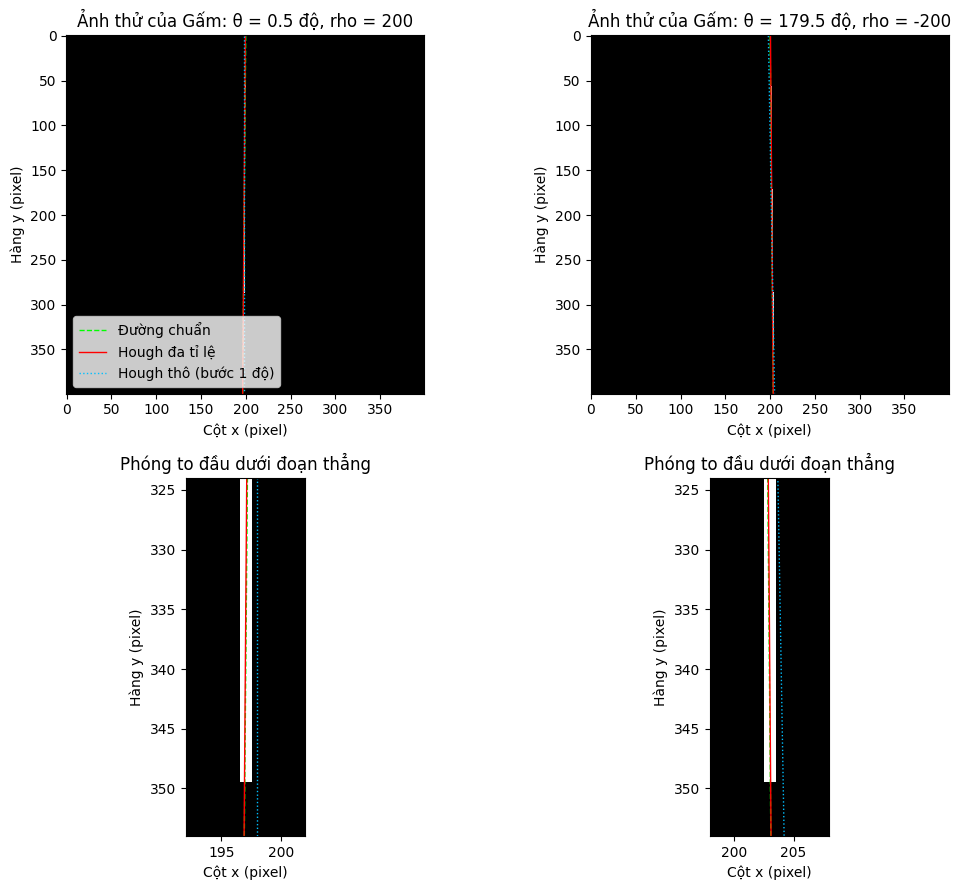

In [43]:
ket_qua_thu = []
sai_so_tho = []
tat_ca_dat = tat_ca_dat_nhom
print("Đối chiếu OpenCV: bước rho = 1 pixel, bước θ = 1 độ, ngưỡng phiếu = 50.")
print("Góc chuẩn | Sai số góc nhóm | Sai số rho nhóm | Sai số góc OpenCV | Sai số rho OpenCV | Kết quả")
for anh, rho0, theta0, rho, theta, ss_goc, ss_rho, ss_n0 in ket_qua_nhom:
    duong_tho = cv2.HoughLines(anh, 1, np.pi / 180, 50)
    if duong_tho is None:
        print(f"{theta0:9.2f} độ | CHƯA ĐẠT: OpenCV không tìm thấy đường")
        tat_ca_dat = False
        continue
    rho_tho, theta_tho = duong_tho[0, 0]
    ss_tho = angle_error(theta0, np.rad2deg(theta_tho))
    ss_rho_tho = rho_error(rho0, theta0, rho_tho, np.rad2deg(theta_tho))
    if rho is None:
        print(f"{theta0:9.2f} độ | CHƯA ĐẠT: hàm nhóm không tìm thấy đường; "
              f"OpenCV: sai số góc {ss_tho:.3f} độ, sai số rho {ss_rho_tho:.3f} pixel")
        tat_ca_dat = False
        continue
    dat = 0 <= theta < np.pi and rho * rho0 > 0 and ss_goc < ss_n0 and ss_goc < ss_tho
    tat_ca_dat = tat_ca_dat and dat
    sai_so_tho.append(ss_tho)
    ket_qua_thu.append((anh, rho0, theta0, rho, theta, rho_tho, theta_tho))
    print(f"{theta0:9.2f} độ | {ss_goc:15.3f} độ | {ss_rho:13.3f} | "
          f"{ss_tho:17.3f} độ | {ss_rho_tho:15.3f} | {'ĐẠT' if dat else 'CHƯA ĐẠT'}")

if len(ket_qua_thu) == len(cac_ca):
    tb_moi = np.mean(sai_so_moi)
    tb_n0 = np.mean(sai_so_n0)
    tb_tho = np.mean(sai_so_tho)
    print(f"\nSai số góc trung bình: Hough đa tỉ lệ {tb_moi:.3f} độ")
    print(f"Hough thô của nhóm: {tb_n0:.3f} độ; Hough thô OpenCV: {tb_tho:.3f} độ")
else:
    print("Không tính trung bình toàn bộ: có trường hợp không tìm thấy đường.")
print("Đối chiếu toàn bộ:", "ĐẠT" if tat_ca_dat else "CHƯA ĐẠT")

if ket_qua_thu:
    fig, axes = plt.subplots(2, len(ket_qua_thu), figsize=(5.5 * len(ket_qua_thu), 9), squeeze=False)
    for cot, (anh, rho0, theta0, rho, theta, rho_tho, theta_tho) in enumerate(ket_qua_thu):
        h, w = anh.shape
        ys, xs = np.nonzero(anh)
        y_cuoi = ys.max()
        x_cuoi = xs[ys == y_cuoi].mean()
        y = np.arange(h)
        cac_duong_ve = [(rho0, np.deg2rad(theta0), "lime", "--", "Đường chuẩn"),
                         (rho, theta, "red", "-", "Hough đa tỉ lệ"),
                         (rho_tho, theta_tho, "deepskyblue", ":", "Hough thô (bước 1 độ)")]
        for hang in range(2):
            ax = axes[hang, cot]
            ax.imshow(anh, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
            for r, t, mau, kieu, nhan in cac_duong_ve:
                x = (r - y * np.sin(t)) / np.cos(t)
                ax.plot(x, y, linestyle=kieu, color=mau, linewidth=1, label=nhan)
            if hang == 0:
                ax.set_xlim(-0.5, w - 0.5)
                ax.set_ylim(h - 0.5, -0.5)
                ax.set_title(f"Ảnh thử của Gấm: θ = {theta0} độ, rho = {rho0:g}")
            else:
                ax.set_xlim(x_cuoi - 5, x_cuoi + 5)
                ax.set_ylim(y_cuoi + 5, y_cuoi - 25)
                ax.set_title("Phóng to đầu dưới đoạn thẳng")
            ax.set_xlabel("Cột x (pixel)")
            ax.set_ylabel("Hàng y (pixel)")
    axes[0, 0].legend(loc="lower left")
    plt.tight_layout()
    plt.show()
